# Experiment 7: PageRank using PySpark

PageRank is the algorithm Google originally used to rank web pages. The idea: a page is important if other important pages link to it.

Here we run it on a tiny toy web of 4 pages, same graph as in the experiment sheet, and watch the ranks settle over a few rounds.

## Setup

Colab doesn't ship Spark by default, so install pyspark first.

In [ ]:
!pip install -q pyspark

In [ ]:
from pyspark.sql import SparkSession
import os

spark = SparkSession.builder.appName("PageRank").master("local[*]").getOrCreate()
sc = spark.sparkContext

## Input data

Each line is "source target", meaning source links to target. Same 6 links as the original experiment:

page1 -> page3
page2 -> page1
page4 -> page1
page3 -> page1
page4 -> page2
page3 -> page4

In [ ]:
links_data = """page1 page3
page2 page1
page4 page1
page3 page1
page4 page2
page3 page4"""

with open("PageLinks.txt", "w") as f:
    f.write(links_data)

## The contribution function

When a page sends its rank forward, it splits that rank equally among all the pages it links to. If page3 links to 2 pages, each one gets half of page3's rank.

In [ ]:
def computeContribs(neighbors, rank):
    for neighbor in neighbors:
        yield (neighbor, rank / len(neighbors))

## Build the link graph

Read the file, split each line into (source, target), then group targets by source. groupByKey gives, for each page, the list of pages it points to.

Note: the original experiment used Python 2 style lambdas like `lambda (page, neighbors): ...`, which Python 3 dropped. Below uses plain tuple indexing instead, same logic.

In [ ]:
linkfile = "file://" + os.path.abspath("PageLinks.txt")

links = sc.textFile(linkfile).map(lambda line: line.split()) \
    .map(lambda pages: (pages[0], pages[1])) \
    .distinct() \
    .groupByKey() \
    .persist()

## Initial ranks

Every page starts out equally important, with a rank of 1.0.

In [ ]:
ranks = links.map(lambda pair: (pair[0], 1.0))

## Running PageRank

Each round:
1. every page sends its rank to its neighbors (computeContribs)
2. each page adds up what it received (reduceByKey)
3. apply the damping factor: new_rank = received * 0.85 + 0.15

The 0.15 keeps a small baseline rank for every page even if nobody links to it, matching the 0.85/0.15 split from the experiment.

Runs for n = 10 iterations, same as the original.

In [ ]:
n = 10

for x in range(n):
    contribs = links.join(ranks).flatMap(
        lambda pr: computeContribs(pr[1][0], pr[1][1])
    )
    ranks = contribs.reduceByKey(lambda v1, v2: v1 + v2) \
        .map(lambda pc: (pc[0], pc[1] * 0.85 + 0.15))

    print("Iteration", x)
    for pair in ranks.collect():
        print(pair)

Iteration 0
('page2', 0.575)
('page4', 0.575)
('page3', 1.0)
('page1', 1.8499999999999999)
Iteration 1
('page4', 0.575)
('page3', 1.7224999999999997)
('page2', 0.394375)
('page1', 1.3081249999999998)
Iteration 2
('page3', 1.2619062499999998)
('page1', 1.4616562499999997)
('page2', 0.394375)
('page4', 0.8820624999999999)
Iteration 3
('page2', 0.5248765624999999)
('page3', 1.3924078124999997)
('page4', 0.6863101562499999)
('page1', 1.3964054687499998)
Iteration 4
('page4', 0.7417733203124999)
('page2', 0.4416818164062499)
('page3', 1.3369446484374998)
('page1', 1.4796002148437497)
Iteration 5
('page1', 1.408884680664062)
('page2', 0.4652536611328124)
('page3', 1.407660182617187)
('page4', 0.7182014755859374)
Iteration 6
('page3', 1.3475519785644525)
('page1', 1.4489568166992184)
('page2', 0.4552356271240233)
('page4', 0.7482555776123045)
Iteration 7
('page1', 1.4276684944305416)
('page4', 0.7227095908898923)
('page3', 1.3816132941943355)
('page2', 0.4680086204852294)
Iteration 8
('page2'

## Final ranks, sorted

In [ ]:
final = ranks.collect()
final.sort(key=lambda pc: pc[1], reverse=True)

for page, rank in final:
    print(page, round(rank, 4))

page1 1.4314
page3 1.3758
page4 0.7295
page2 0.4633


In [ ]:
spark.stop()

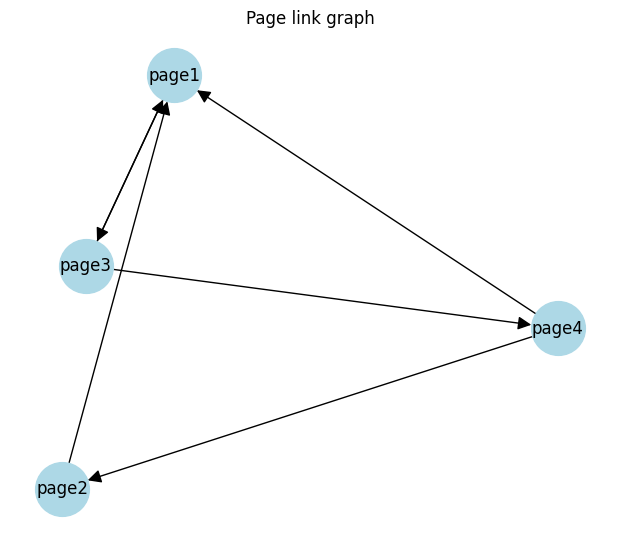

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

edges = [
    ("page1", "page3"),
    ("page2", "page1"),
    ("page4", "page1"),
    ("page3", "page1"),
    ("page4", "page2"),
    ("page3", "page4"),
]

G = nx.DiGraph()
G.add_edges_from(edges)

plt.figure(figsize=(6, 5))
pos = nx.spring_layout(G, seed=1)
nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=1500,
        arrowsize=20, font_size=12)
plt.title("Page link graph")
plt.show()